(0.0, 1e-08)

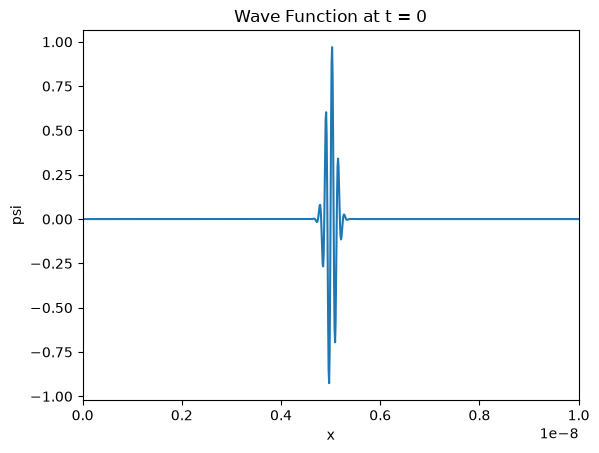

In [1]:
from numpy import copy

def banded(Aa,va,up,down):

    # Copy the inputs and determine the size of the system
    A = copy(Aa)
    v = copy(va)
    N = len(v)

    # Gaussian elimination
    for m in range(N):

        # Normalization factor
        div = A[up,m]

        # Update the vector first
        v[m] /= div
        for k in range(1,down+1):
            if m+k<N:
                v[m+k] -= A[up+k,m]*v[m]

        # Now normalize the pivot row of A and subtract from lower ones
        for i in range(up):
            j = m + up - i
            if j<N:
                A[i,j] /= div
                for k in range(1,down+1):
                    A[i+k,j] -= A[up+k,m]*A[i,j]

    # Backsubstitution
    for m in range(N-2,-1,-1):
        for i in range(up):
            j = m + up - i
            if j<N:
                v[m] -= A[i,j]*v[j]

    return v

import numpy as np
import matplotlib.pyplot as plt
import cmath as cm
from math import*


#the constants are defined as:
m = 9.109e-31
L=10**-8
x_0= L/2
kap = 5*10**10
sig =10**-10
h_bar=1.0545718e-34
i= complex(0,1)

N=1000
a=L/N
h=10**-18


#The matrix is set ip as follows:
a_1=1+(h*i*h_bar/(2*m*a*a))
a_2 = -h*i*h_bar/(4*m*a*a)
b_1=1-(h*i*h_bar/(2*m*a*a))
b_2= h*i*h_bar/(4*m*a*a)


#The wavefunction is defined as follows:
def psi_0(x):
    return (exp(-((x-x_0)**2)/(2*(sig**2))))*(cm.exp(i*kap*x))


# array initialization
x_g = np.linspace (0,L,N+1)
v_g = np.zeros(N+1, complex)

# wavefunction initialization

psi_initial = np.array(list(map(psi_0, x_g)), complex)
psi = psi_initial

A_banded = np.zeros([3, N+1],complex)
A_banded[0,:]=a_2
A_banded[1,:]=a_1
A_banded[2,:]=a_2  


v_g[1:N] = b_1*psi[1:N] +b_2*(psi[2:N+1]+ psi[0:N-1])
psi = banded(A_banded,v_g,1,1)
plt.figure(1)
# plt.plot(x_g,psi)
plt.plot(x_g, np.real(psi))
plt.xlabel("x")
plt.ylabel("psi")
plt.title("Wave Function at t = 0")
plt.xlim(0,1e-8)

In [2]:
plt.rcParams['animation.embed_limit'] = 24.0  
import matplotlib.animation as animation
from IPython.display import HTML


psi = np.array([exp(-((x - x_0)**2) / (2 * (sig**2))) * cm.exp(i * kap * x) for x in x_g], complex)

fig, ax = plt.subplots(figsize=(10, 6))
line, = ax.plot(x_g, psi.real)
ax.set_xlim(0, L)
ax.set_ylim(-1.0, 1.0)
ax.grid(True)

def update(frame):
    global psi
    if frame > 0:
        # Your exact loop step:
        v_g[1:N] = b_1 * psi[1:N] + b_2 * (psi[2:N + 1] + psi[0:N - 1])
        psi = banded(A_banded, v_g, 1, 1)
        
    line.set_ydata(psi.real)
    ax.set_title("Wave Function at t = 0" if frame == 0 else f"Wave Function after {frame} steps")
    return line,

ani = animation.FuncAnimation(fig, update, frames=500, interval=75, blit=True)
plt.close(fig)
HTML(ani.to_jshtml())